# M5 — Advanced Segmentation, KPIs and Stakeholder Brief (Path B)

**Project question:** Can publicly available DPWH flood control project data reveal unusual geographic, financial, and contractor-related patterns that may indicate areas requiring further audit or investigation between 2022 and 2025?

**Path chosen: Path B (Alt Track).** The question is about description, segmentation and prioritising review, not predicting a numeric or yes/no outcome, so a predictive model would be forced and is not used.

| Section | Week | Deliverable |
|---|---|---|
| 1 | 17 | Segmentation analysis |
| 2 | 18 | KPI framework with trends |
| 3 | 19 | One-page stakeholder brief |
| 4 | 20 | Pipeline integration, outputs and limitations |

> The notebook imports its calculations from `scripts/analysis/m5_segmentation_kpis.py`, so the script and notebook always show the same numbers. All results are **patterns that may merit review**, not evidence of wrongdoing.

In [1]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/processed/dpwh_flood_control_analysis_ready.csv").exists())
sys.path.insert(0, str(ROOT / "scripts/analysis")); import m5_segmentation_kpis as m5
import os; os.chdir(ROOT)   # the script uses repo-relative paths

d = m5.prepare(m5.load())
prov = m5.province_concentration(d); kq = m5.kpi_quarterly(d); short = m5.review_shortlist(prov)
print(d.shape, "| new columns:", [c for c in d.columns if c in ("completion_year","completion_quarter","work_group","over_budget","cost_zscore_region_year","is_outlier_time_adjusted")])

(9827, 33) | new columns: ['completion_year', 'completion_quarter', 'work_group', 'over_budget', 'cost_zscore_region_year', 'is_outlier_time_adjusted']


## 1. Advanced segmentation and cohort analysis (Week 17)

### Segmentation plan
| Segment dimension | Why it matters | Comparison metric |
|---|---|---|
| Island group × completion-year cohort | Tests whether geography or timing explains where costly projects appear | High-cost outlier rate, average cost |
| Type of work × island group | Different structures cost different amounts, so comparing across types can mislead | Average cost, outlier rate |
| Contractor size tier (projects won) | Shows whether value sits with many occasional contractors or a few repeat winners | Share of projects and of value |

**Time-adjusted flag.** The original `is_high_cost_outlier` compares each project with its region’s average across *all* years. Because costs rose over time, a later project can look expensive for its region simply because of when it was completed. `is_outlier_time_adjusted` uses the same cut-off but compares within region **and** completion year.

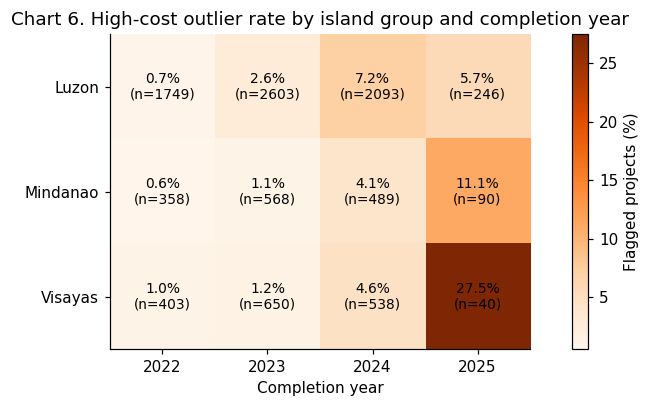

,mainisland,completion_year,projects,avg_cost_php_m,outlier_rate,outlier_rate_time_adjusted
0,Luzon,2022,1749,41.2,0.7,3.5
1,Luzon,2023,2603,53.3,2.6,2.5
2,Luzon,2024,2093,66.4,7.2,3.4
3,Luzon,2025,246,72.2,5.7,1.6
4,Mindanao,2022,358,43.9,0.6,3.1
5,Mindanao,2023,568,58.9,1.1,3.3
6,Mindanao,2024,489,74.2,4.1,3.3
7,Mindanao,2025,90,77.0,11.1,2.2
8,Visayas,2022,403,39.8,1.0,6.0
9,Visayas,2023,650,52.0,1.2,1.4


In [2]:
seg1 = m5.segment_island_year(d)
m5.fig_island_year(seg1); plt.show()
display(seg1.assign(avg_cost_php_m=seg1.avg_cost_php_m.round(1), outlier_rate=(seg1.outlier_rate*100).round(1), outlier_rate_time_adjusted=(seg1.outlier_rate_time_adjusted*100).round(1)))

**Chart 6 interpretation.** The original outlier rate climbs with completion year in every island group (Luzon 0.7% in 2022 to 7.2% in 2024; Mindanao 0.6% to 4.1%; Visayas 1.0% to 4.6%). The time-adjusted rate stays in a narrow band with no steady rise, which means most of that climb reflects rising costs over time rather than more abnormal projects. The 2025 cells have few projects (for example Visayas n = 40), so they should not be read as a trend.

In [3]:
seg2 = m5.segment_work_island(d)
pv = seg2.pivot(index="work_group", columns="mainisland", values="avg_cost_php_m").round(1)
cnt = seg2.pivot(index="work_group", columns="mainisland", values="projects")
display(pv.style.set_caption("Average contract cost (PHP millions) by type of work and island group"))
display(cnt.style.set_caption("Number of projects (small cells are unreliable)"))
display(d.groupby("work_group")[m5.COST].mean().div(1e6).round(1).sort_values().rename("overall avg cost (PHP M)").to_frame())

mainisland,Luzon,Mindanao,Visayas
work_group,,,
Drainage Structure,21.300000,35.600000,16.300000
Flood Mitigation Structure,56.900000,63.800000,52.900000
Other,53.900000,66.700000,45.800000
Revetment,68.800000,67.200000,57.300000
Slope Protection Structure,58.200000,45.400000,74.600000


mainisland,Luzon,Mindanao,Visayas
work_group,,,
Drainage Structure,430,142,106
Flood Mitigation Structure,4181,966,1196
Other,1087,106,141
Revetment,386,252,95
Slope Protection Structure,607,39,93


,overall avg cost (PHP M)
work_group,
Drainage Structure,23.5
Other,54.1
Flood Mitigation Structure,57.2
Slope Protection Structure,59.6
Revetment,66.8


**Type-of-work interpretation.** Project type changes the cost level a lot: drainage structures average about ₱23.5M overall against about ₱66.8M for revetments, and Luzon drainage projects average ₱21.3M against ₱35.6M in Mindanao. Cells such as slope protection in Mindanao (n = 39) are too small to compare. A cost flag that ignores project type will therefore mix real anomalies with ordinary differences between structures, which is the main reason to benchmark by type in the next iteration.

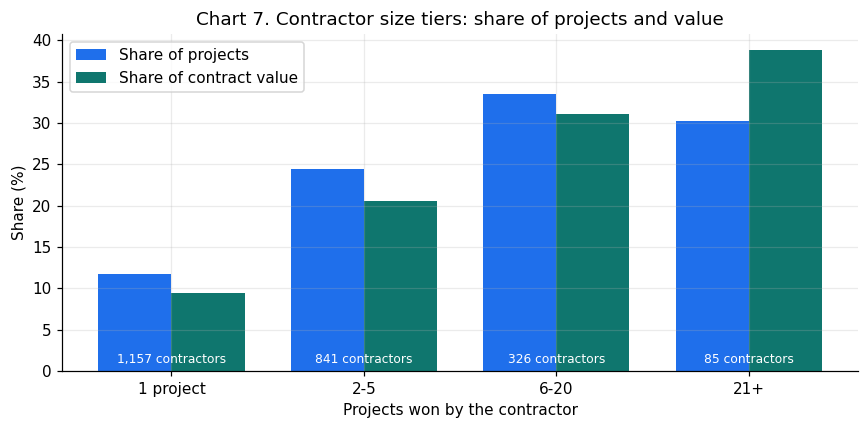

,tier,contractors,projects,share_of_projects,share_of_value,value_bn
0,1 project,1157,1157,11.8,9.5,51.5
1,2-5,841,2405,24.5,20.6,111.9
2,6-20,326,3295,33.5,31.1,169.3
3,21+,85,2970,30.2,38.8,210.9


In [4]:
seg3 = m5.segment_contractor_tier(d)
m5.fig_contractor_tier(seg3); plt.show()
display(seg3.assign(value_bn=(seg3.value/1e9).round(1), share_of_projects=(seg3.share_of_projects*100).round(1), share_of_value=(seg3.share_of_value*100).round(1)).drop(columns="value"))

**Chart 7 interpretation.** The 85 contractors that won 21 or more projects (about 3.5% of 2,409 names) hold 38.8% of contract value, while the 1,157 contractors with a single project hold 9.5%. Value is therefore concentrated in a group of repeat winners even though no single contractor dominates nationally. Whether that reflects capacity, regional packaging or something else cannot be told from this data; it only shows where repeat awards sit.

## 2. KPI development and metric framework (Week 18)

Each KPI traces back to the problem statement (geographic, financial and contractor patterns that may justify review).

| KPI | Definition | Formula or logic | Why it matters |
|---|---|---|---|
| **KPI 1 — High-cost outlier rate** | Share of completed projects whose cost is unusually high for their region | flagged projects ÷ all projects (also shown time-adjusted) | Financial pattern: where costs depart most from the norm |
| **KPI 2 — Average contract cost** | Mean contract cost per project, in PHP millions | sum of contract cost ÷ number of projects | Context for KPI 1: shows whether costs themselves are drifting |
| **KPI 3 — Top-10 contractor share of value** | Share of total contract value held by the ten largest contractors | top-10 contractor value ÷ total value | Contractor pattern at national level |
| **KPI 4 — Provincial top-contractor share** | How much of a province’s value one contractor holds (median across provinces with 30+ projects) | largest contractor value ÷ province value | Geographic and contractor pattern at local level, where concentration shows up |
| **KPI 5 — Over-budget rate** | Share of contracts whose cost exceeds the approved budget | contracts with cost > approved budget ÷ contracts with a budget | Financial control signal |

**KPI vs vanity metric.** Total project count and total cost by region are kept as context, not KPIs: they mostly reflect how big a region is and do not tell an auditor where to look.

,kpi,name,value,unit
0,KPI 1,High-cost outlier rate,0.033,share of projects
1,KPI 2,Average contract cost (PHP M),55.326,PHP millions
2,KPI 3,Top-10 contractor share of value,0.103,share of value
3,KPI 4,Median provincial top-contractor share (69 pro...,0.190,share of province value
4,KPI 5,Over-budget rate,0.079,share of projects with a budget


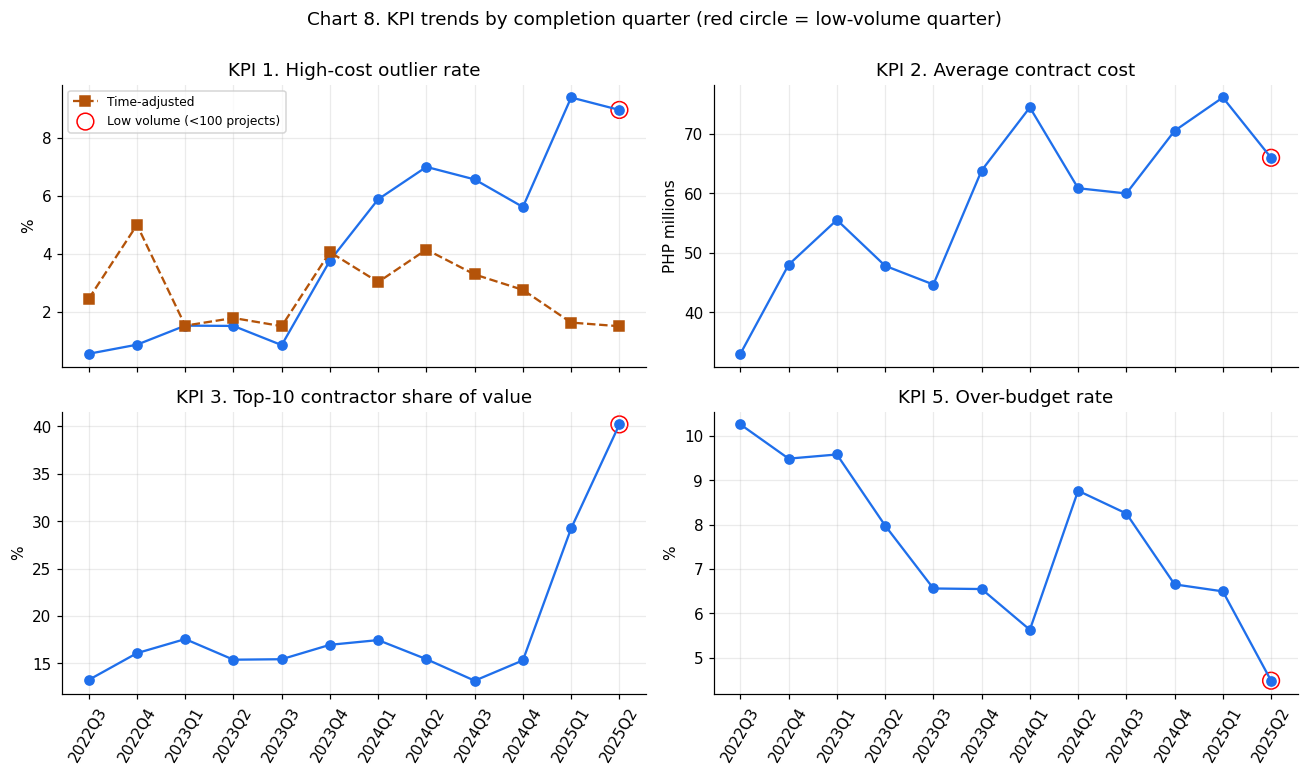

,quarter,projects,kpi1_outlier_rate,kpi1b_outlier_rate_time_adjusted,kpi2_avg_cost_php_m,kpi3_top10_contractor_share,kpi5_over_budget_rate,low_volume
0,2022Q3,1107,0.005,0.024,32.987,0.133,0.103,False
1,2022Q4,1403,0.009,0.050,47.958,0.161,0.095,False
2,2023Q1,661,0.015,0.015,55.488,0.176,0.096,False
3,2023Q2,732,0.015,0.018,47.775,0.154,0.080,False
4,2023Q3,1070,0.008,0.015,44.627,0.154,0.066,False
5,2023Q4,1358,0.038,0.041,63.795,0.170,0.065,False
6,2024Q1,630,0.059,0.030,74.402,0.175,0.056,False
7,2024Q2,701,0.070,0.041,60.816,0.154,0.088,False
8,2024Q3,915,0.066,0.033,59.936,0.132,0.083,False
9,2024Q4,874,0.056,0.027,70.467,0.153,0.067,False


In [5]:
display(m5.kpi_summary(d, prov).assign(value=lambda x: x.value.round(3)))
m5.fig_kpi_trends(kq); plt.show()
display(kq.round(3))

**KPI interpretation.** The original outlier rate (KPI 1) rises from 0.5% in 2022 Q3 to 9.4% in 2025 Q1, but the time-adjusted version stays between about 1.5% and 5%, while the average contract cost (KPI 2) rises from ₱33.0M to ₱76.1M. Most of the apparent increase in “unusual” projects is therefore a cost-level effect, and KPI 1 should always be read next to KPI 2 or in its time-adjusted form. The top-10 contractor share (KPI 3) holds at 13–18% through 2024 and the over-budget rate (KPI 5) drifts down from 10.3% to about 6–9%; the 2025 figures rest on far fewer projects (309 in Q1, 67 in Q2), so they are not a trend.

In [6]:
big = prov[prov.projects >= m5.MIN_PROJECTS]
print(f"KPI 4: median provincial top-contractor share = {big.top1_share.median():.1%} across {len(big)} provinces")
display(big.head(8)[["province","region","projects","contractors","top1_share","top3_share"]].round(3))
print("Regions, original vs time-adjusted outlier rate:")
display(d.groupby("region").agg(projects=("project_id","count"), original=("is_high_cost_outlier","mean"), time_adjusted=("is_outlier_time_adjusted","mean")).sort_values("time_adjusted", ascending=False).head(5).round(3))

KPI 4: median provincial top-contractor share = 19.0% across 69 provinces


,province,region,projects,contractors,top1_share,top3_share
6,Apayao,Cordillera Administrative Region,34,15,0.503,0.689
51,Misamis Occidental,Region X,33,13,0.435,0.694
48,Marinduque,Region IV-B,70,32,0.414,0.570
15,Bukidnon,Region X,110,32,0.389,0.632
67,Romblon,Region IV-B,87,20,0.387,0.671
0,Abra,Cordillera Administrative Region,105,12,0.385,0.795
71,Sorsogon,Region V,129,24,0.362,0.537
68,Samar,Region VIII,55,15,0.328,0.605


Regions, original vs time-adjusted outlier rate:


,projects,original,time_adjusted
region,,,
Region IV-B,498,0.096,0.070
Cordillera Administrative Region,352,0.031,0.057
Region X,428,0.026,0.054
Region VIII,514,0.031,0.045
Region I,851,0.032,0.041


**Geographic check.** Region IV-B has the highest outlier rate under both the original flag (9.6%) and the time-adjusted flag (7.0%), so the earlier M4 finding holds after accounting for time. Oriental Mindoro stays high (17.3% original, 14.4% adjusted), as do Abra and La Union. Provincial concentration (KPI 4) is a separate pattern: Apayao (50%), Misamis Occidental (43%) and Marinduque (41%) lead, with small provinces at the top of the list needing extra care.

### Review shortlist
Provinces with 30+ projects that are in the **top quartile for top-contractor share** *and* above the **median time-adjusted outlier rate**. This is a priority list for document review, not a list of problems.

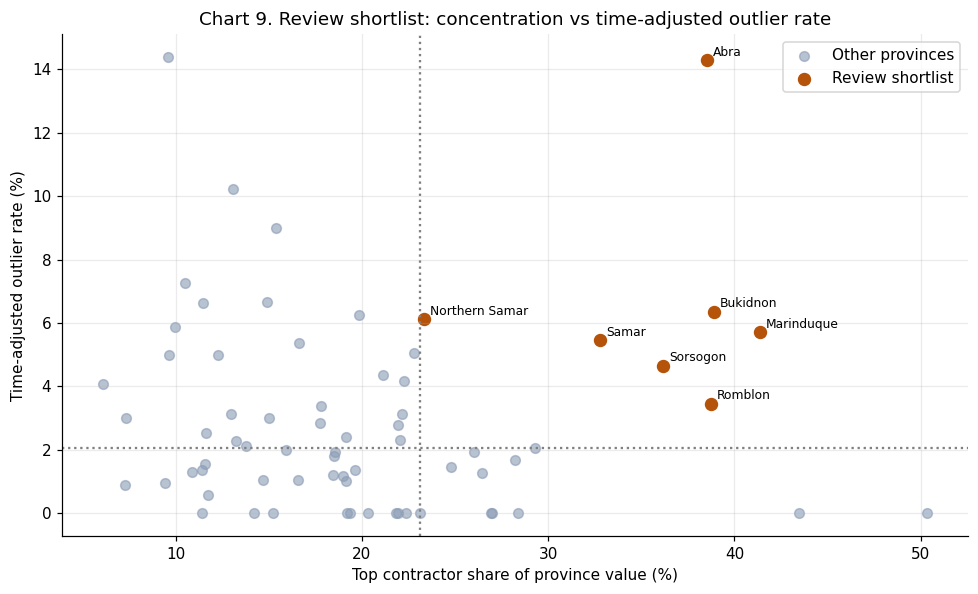

,province,region,projects,top1_share,top3_share,outlier_rate_time_adjusted
48,Marinduque,Region IV-B,70,0.414,0.570,0.057
15,Bukidnon,Region X,110,0.389,0.632,0.064
67,Romblon,Region IV-B,87,0.387,0.671,0.034
0,Abra,Cordillera Administrative Region,105,0.385,0.795,0.143
71,Sorsogon,Region V,129,0.362,0.537,0.047
68,Samar,Region VIII,55,0.328,0.605,0.055
56,Northern Samar,Region VIII,49,0.233,0.482,0.061


In [7]:
m5.fig_shortlist(prov, short); plt.show()
display(short[["province","region","projects","top1_share","top3_share","outlier_rate_time_adjusted"]].round(3))

**Shortlist interpretation.** Seven provinces meet both conditions: Marinduque, Bukidnon, Romblon, Abra, Sorsogon, Samar and Northern Samar. Abra stands out because it is high on both measures (38.5% top-contractor share and a 14.3% time-adjusted flag rate). The shortlist and the flag-rate list differ (Oriental Mindoro has a high flag rate but low concentration at 9.6%), so using both lenses gives a fuller picture than either alone.

## 3. Stakeholder narrative and policy brief (Week 19)

A one-page plain-language version is saved as `docs/stakeholder_brief.pdf` and reproduced here.

---

### Where a closer look at DPWH flood control spending may be warranted
**For:** audit teams, oversight bodies and researchers

#### Context
This brief uses public records of 9,827 completed DPWH flood control projects (July 2022 to May 2025, about ₱544 billion in contract value). The question: do the records show patterns that suggest where auditors should look first?

#### Main finding
There is no nationwide red flag. The leads are local. In most provinces no contractor dominates (the typical top contractor holds about 19% of a province’s contract value), but in a few, one contractor holds far more. Separately, a small share of projects (about 3%) cost much more than comparable projects in the same region, and these cluster in Region IV-B, especially Oriental Mindoro, and in Abra. Costs also rose steadily over the period (average contract ₱33M in mid-2022 to ₱76M in early 2025), so projects must be compared with others from the same year.

#### Why it matters
Audit time is limited. These patterns can help decide where to start, and the time adjustment avoids wrongly flagging later projects just because prices rose.

#### Recommended actions
1. **Start document review with the seven provinces where both patterns overlap:** Marinduque, Bukidnon, Romblon, Abra, Sorsogon, Samar and Northern Samar, plus Oriental Mindoro for its high cost-flag rate.
2. **Check flagged projects against DPWH Project DIME and COA reports before drawing any conclusion.** Higher costs can reflect terrain, design or project size that this data does not capture.
3. **Publish standard contractor names and IDs and project size in the open data.** Truncated and inconsistent names make concentration figures approximate.

#### Caution
These are statistical indicators, not evidence of wrongdoing. The data covers completed projects only and has no information on how contracts were awarded.

---

## 4. Pipeline integration and limitations (Week 20)

### Run order (from the repository root)
```text
1. python scripts/ingest.py                              # raw data (needs Kaggle credentials; skip if data/raw exists)
2. python scripts/transform.py                           # cleaned data
3. python scripts/advanced_transform.py                  # analysis-ready data
4. python scripts/analysis/m5_segmentation_kpis.py       # segments, KPIs, shortlist, Chart 6-9
5. jupyter notebook notebooks/M5_segmentation_kpis_brief.ipynb
```
Or run steps 2–4 together with `python scripts/run_pipeline.py`.

### Saved outputs
| File | Content |
|---|---|
| `data/processed/m5_segment_island_year.csv` | Island × completion-year segments |
| `data/processed/m5_segment_work_island.csv` | Type of work × island segments |
| `data/processed/m5_segment_contractor_tier.csv` | Contractor size tiers |
| `data/processed/m5_province_concentration.csv` | Province concentration and flag rates |
| `data/processed/m5_kpi_quarterly.csv` / `m5_kpi_summary.csv` | KPI trends and headline values |
| `data/processed/m5_review_shortlist.csv` | Review shortlist |
| `output/figures/m5_chart6…9*.png` | Charts 6–9 |
| `docs/stakeholder_brief.pdf` | One-page brief |

### Assumptions and limitations
- Completed projects only, July 2022 to May 2025; ongoing and cancelled projects are not in the file.
- The time-adjusted flag benchmarks by region and year but not by project type or size; type-adjusted benchmarking is the next improvement.
- Contractor names are as recorded; truncated or variant names undercount some contractors, and joint ventures (1,338 rows) are not split between partners.
- Provinces under 30 projects are excluded from concentration rankings because the figures are noisy.
- 2025 quarters have far fewer projects, so their KPI values are not trends.
- No causal claim is made; nothing here indicates irregularity without checking against source documents.